In [1]:
import sys
sys.path.append("..")
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.db import query

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
SQL = Path("../sql/analyses")

count   27,026.00
mean        59.29
std         78.29
min          1.00
25%         13.00
50%         32.00
75%         70.00
max        714.00
Name: gap_days, dtype: float64
Gaps longer than 30 days: 51.0%
Gaps longer than 60 days: 29.2%
Gaps longer than 90 days: 19.4%
Gaps longer than 120 days: 13.5%
Gaps longer than 180 days: 7.3%
Gaps longer than 270 days: 3.4%


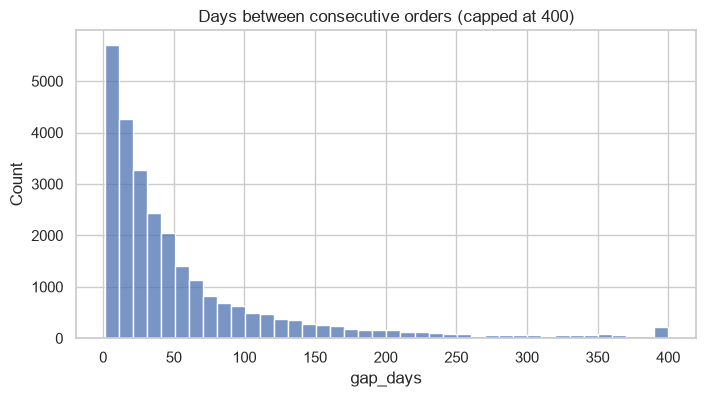

In [2]:
gaps = query((SQL / "order_gaps.sql").read_text())
print(gaps["gap_days"].describe())
for d in (30, 60, 90, 120, 180, 270):
    print(f"Gaps longer than {d} days: {(gaps['gap_days'] > d).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(gaps["gap_days"].clip(upper=400), bins=40, ax=ax)
ax.set_title("Days between consecutive orders (capped at 400)")
plt.show()

## Findings
- Median gap between orders is 32 days; 81% of observed gaps are under 90 days.
- With a 180-day lookback and 90-day horizon, churn ranges from 38% to 62% across snapshots, driven by seasonality.
- Other definitions shift the level but not the shape. Chosen: 180-day lookback, 90-day horizon.

In [3]:
sql = (SQL / "churn_rate_by_snapshot.sql").read_text()
frames = []
for lookback, horizon in [(180, 90), (180, 60), (180, 120), (365, 90)]:
    df = query(sql, {"lookback": lookback, "horizon": horizon})
    df["definition"] = f"{lookback}d active / {horizon}d horizon"
    frames.append(df)
churn = pd.concat(frames, ignore_index=True)
churn[churn["definition"] == "180d active / 90d horizon"]

,snapshot_date,active_customers,churned_customers,churn_rate_pct,definition
0,2010-06-01,2652,1325,50.00,180d active / 90d horizon
1,2010-07-01,2737,1343,49.10,180d active / 90d horizon
2,2010-08-01,2813,1209,43.00,180d active / 90d horizon
3,2010-09-01,2822,1072,38.00,180d active / 90d horizon
4,2010-10-01,2899,1219,42.00,180d active / 90d horizon
5,2010-11-01,3196,1619,50.70,180d active / 90d horizon
6,2010-12-01,3465,2147,62.00,180d active / 90d horizon
7,2011-01-01,3403,2119,62.30,180d active / 90d horizon
8,2011-02-01,3348,2020,60.30,180d active / 90d horizon
9,2011-03-01,3338,1924,57.60,180d active / 90d horizon


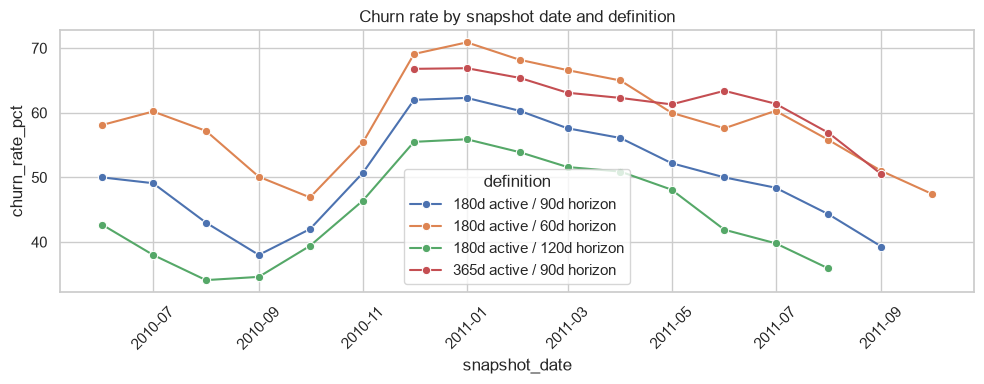

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=churn, x="snapshot_date", y="churn_rate_pct",
             hue="definition", marker="o", ax=ax)
ax.set_title("Churn rate by snapshot date and definition")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()